# Prototype: does the shade-correction method work? (synthetic data)

**What this notebook proves, and what it does not.**
It simulates a made-up printer + kiln and tests one claim from the case study:
*if the printer responds to colour changes in a roughly steady way, a calibrated correction calculator needs about 1-2 correction rounds instead of many.*

It does **not** prove anything about real tiles. Every number is invented. The "guess and check" baseline is a crude stand-in; the real "before" number must be measured in week 1.

**How the simulation works**
1. A hidden printer has 6 colour channels. Changing channel *j* by 1% moves the fired tile's colour (L, a, b) at each of 4 spots by a fixed amount, plus a small curved part.
2. The master tile is what the printer gives with no changes. Today's tile is off because of a hidden drift in the channels.
3. Setup: 13 test tiles (one unchanged, each channel +3% and -3%) give a sensitivity table.
4. Each round: measure, compute the difference from the master, ask the calculator for channel changes, apply, measure again.
5. Pass rule: average colour difference (CIEDE2000) <= 1.0 and no spot above 1.5.


In [1]:
"""Synthetic printer + correction method. Every number here is made up."""
import numpy as np
from skimage.color import deltaE_ciede2000

N_CH, N_REG = 6, 4      # 6 printer channels, 4 matched spots measured on the tile


def make_printer(rng, nonlin=0.02):
    """A hidden 'printer + kiln'. Fired Lab at each spot = base + S @ c + curvature, c = channel changes in %."""
    base = np.column_stack([rng.uniform(40, 75, N_REG),     # L
                            rng.uniform(-10, 25, N_REG),    # a
                            rng.uniform(-5, 30, N_REG)])    # b
    S = rng.normal(0, 0.35, size=(N_REG, 3, N_CH))          # Lab change per +1% of each channel, per spot
    Q = rng.normal(0, 1, size=(N_REG, 3, N_CH))             # the "not a straight line" part

    def fired(c, noise=0.0):
        lab = base + np.einsum('rkj,j->rk', S, c) + nonlin * np.einsum('rkj,j->rk', Q, c ** 2)
        return lab + rng.normal(0, noise, lab.shape)        # measurement noise of the spectrophotometer
    return fired


def dE(a, b):
    """CIEDE2000 colour difference, one value per spot (huge values if a run has blown up)."""
    with np.errstate(all="ignore"):
        e = deltaE_ciede2000(np.clip(a, -200, 200), np.clip(b, -200, 200))
    return np.nan_to_num(e, nan=100.0)


def passed(e, thr_mean=1.0, thr_max=1.5):
    return e.mean() <= thr_mean and e.max() <= thr_max


# ---------- our method ----------
def calibrate(fired, noise, step=3.0):
    """13 tiles: centre + (+step, -step) per channel. Central differences give the sensitivity table."""
    S_hat = np.zeros((N_REG * 3, N_CH))
    for j in range(N_CH):
        up, dn = np.zeros(N_CH), np.zeros(N_CH)
        up[j], dn[j] = step, -step
        S_hat[:, j] = ((fired(up, noise) - fired(dn, noise)) / (2 * step)).ravel()
    return S_hat


def suggest(S_hat, diff, lam=0.05, max_step=6.0):
    """Smallest channel change that cancels the measured difference (ridge least squares).
    Each channel is capped at +-max_step % per round as a safety limit."""
    c = -np.linalg.solve(S_hat.T @ S_hat + lam * np.eye(N_CH), S_hat.T @ diff.ravel())
    return np.clip(c, -max_step, max_step)


def update_table(S_hat, dc, d_diff):
    """After a real round, nudge the sensitivity table toward what was actually seen (Broyden update).
    dc = channel change just applied, d_diff = how the measured difference actually moved."""
    denom = float(dc @ dc)
    if denom < 1e-9:
        return S_hat
    return S_hat + np.outer(d_diff - S_hat @ dc, dc) / denom


# ---------- crude stand-in for "guess and check" ----------
def guess_variants(rng, fired, diff, n_variants=7):
    """Person looks at the lightness error and nudges 1-2 influential channels by a guess ~40% off.
    They print n_variants such guesses and keep whichever fired closest."""
    feel = np.array([(fired(np.eye(N_CH)[j]) - fired(np.zeros(N_CH)))[:, 0].mean() for j in range(N_CH)])
    top = np.argsort(-np.abs(feel))[:3]
    mean_dL = diff[:, 0].mean()
    out = []
    for _ in range(n_variants):
        c = np.zeros(N_CH)
        for j in rng.choice(top, size=rng.integers(1, 3), replace=False):
            c[j] = -mean_dL / feel[j] * rng.uniform(0.3, 1.5) * rng.choice([1, 1, -1])
        out.append(c)
    return out


def run_changeover(rng, noise=0.25, nonlin=0.02, drift=4.0, max_rounds=6, mode="model"):
    """Returns (rounds needed, mean-ΔE after each round). rounds = max_rounds+1 means 'did not converge'."""
    fired = make_printer(rng, nonlin)
    master = fired(np.zeros(N_CH), noise)
    c = rng.normal(0, drift, N_CH)                     # hidden reason today's tile is off the master
    S_hat = calibrate(fired, noise) if mode in ("model", "model+learn") else None
    hist, prev = [], None
    hist = []
    for rnd in range(max_rounds + 1):
        sample = fired(c, noise)
        e = dE(sample, master)
        hist.append(e.mean())
        if passed(e):
            return rnd, hist
        if rnd == max_rounds:
            break
        diff = sample - master
        if mode == "model+learn" and prev is not None:
            S_hat = update_table(S_hat, prev[0], (diff - prev[1]).ravel())
        if mode in ("model", "model+learn"):
            dc = suggest(S_hat, diff)
            prev = (dc, diff)
            c = c + dc
        else:                                          # print 7 guesses, keep the best one
            best_c, best_e = c, e.mean()
            for dc in guess_variants(rng, fired, diff):
                e2 = dE(fired(c + dc, noise), master).mean()
                if e2 < best_e:
                    best_c, best_e = c + dc, e2
            c = best_c
    return max_rounds + 1, hist


def experiment(n=300, seed=0, **kw):
    rng = np.random.default_rng(seed)
    r = np.array([run_changeover(rng, **kw)[0] for _ in range(n)])
    return r


In [2]:
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline

## 1. One changeover, step by step

In [3]:
rng = np.random.default_rng(3)
rounds, hist = run_changeover(rng, mode="model")
print("Corrections needed:", rounds)
for i, h in enumerate(hist):
    print(f"  after {i} corrections: average colour difference = {h:.2f}")

Corrections needed: 2
  after 0 corrections: average colour difference = 3.00
  after 1 corrections: average colour difference = 1.11
  after 2 corrections: average colour difference = 0.56


## 2. 300 simulated changeovers: calculator vs. guess-and-check

Calibrated calculator        mean corrections 1.72 | passed within 2:  94% | never passed in 6:   0%
Guess and check (crude)      mean corrections 6.84 | passed within 2:   2% | never passed in 6:  96%


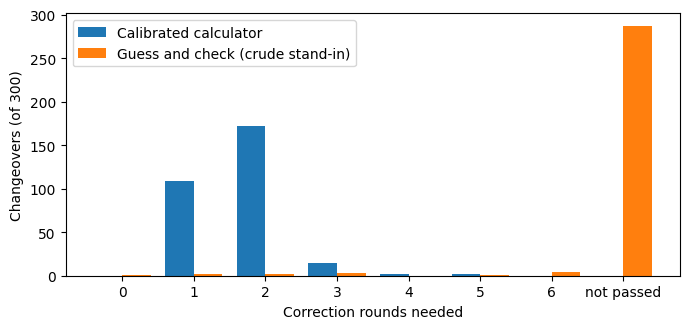

In [4]:
model = experiment(mode="model", seed=1)
guess = experiment(mode="guess", seed=1)

def row(tag, r):
    print(f"{tag:28s} mean corrections {r.mean():.2f} | passed within 2: {np.mean(r<=2):4.0%} | never passed in 6: {np.mean(r>6):4.0%}")
row("Calibrated calculator", model)
row("Guess and check (crude)", guess)

fig, ax = plt.subplots(figsize=(7,3.4))
bins = np.arange(-0.5, 8.5, 1)
ax.hist([model, guess], bins=bins, label=["Calibrated calculator", "Guess and check (crude stand-in)"])
ax.set_xticks(range(0,8)); ax.set_xticklabels(["0","1","2","3","4","5","6","not passed"])
ax.set_xlabel("Correction rounds needed"); ax.set_ylabel("Changeovers (of 300)")
ax.legend(); plt.tight_layout(); plt.savefig("rounds.png", dpi=130); plt.show()

**Reading this honestly.** The calculator passes in about 1-2 corrections in this simulation. The guess-and-check baseline is a strawman: I made it deliberately naive, so do not quote its numbers as "today's performance". The real baseline comes from the client's last ~20 changeovers.

## 3. Where it breaks (the stress tests)

In [5]:
def show(tag, **kw):
    r = experiment(mode="model", seed=2, **kw)
    row(tag, r)

print("Measurement noise (std of each Lab reading; 0.25 is a decent lab device):")
for n in [0.1, 0.25, 0.5, 1.0]:
    show(f"  noise {n}", noise=n)
print()
print("Non-straight-line response (curvature; 0.02 = nearly straight):")
for nl in [0.02, 0.05, 0.1, 0.3]:
    show(f"  curvature {nl}", nonlin=nl)
print()
print("Size of today's drift (std of hidden channel offset, in %):")
for d in [1.0, 2.0, 4.0, 6.0]:
    show(f"  drift {d}%", drift=d)

Measurement noise (std of each Lab reading; 0.25 is a decent lab device):


  noise 0.1                  mean corrections 1.51 | passed within 2:  95% | never passed in 6:   0%


  noise 0.25                 mean corrections 1.69 | passed within 2:  94% | never passed in 6:   0%


  noise 0.5                  mean corrections 3.31 | passed within 2:  39% | never passed in 6:   9%


  noise 1.0                  mean corrections 6.98 | passed within 2:   0% | never passed in 6:  99%

Non-straight-line response (curvature; 0.02 = nearly straight):
  curvature 0.02             mean corrections 1.69 | passed within 2:  94% | never passed in 6:   0%


  curvature 0.05             mean corrections 2.96 | passed within 2:  51% | never passed in 6:   9%


  curvature 0.1              mean corrections 5.60 | passed within 2:  15% | never passed in 6:  64%


  curvature 0.3              mean corrections 6.97 | passed within 2:   0% | never passed in 6:  99%

Size of today's drift (std of hidden channel offset, in %):
  drift 1.0%                 mean corrections 0.69 | passed within 2: 100% | never passed in 6:   0%


  drift 2.0%                 mean corrections 1.01 | passed within 2: 100% | never passed in 6:   0%
  drift 4.0%                 mean corrections 1.69 | passed within 2:  94% | never passed in 6:   0%


  drift 6.0%                 mean corrections 2.33 | passed within 2:  67% | never passed in 6:   0%


In [6]:
print("Does updating the table after each round help when the response is curved (curvature 0.1)?")
for m in ["model", "model+learn"]:
    r = experiment(mode=m, seed=2, nonlin=0.1)
    row(f"  {m}", r)

Does updating the table after each round help when the response is curved (curvature 0.1)?


  model                      mean corrections 5.60 | passed within 2:  15% | never passed in 6:  64%


  model+learn                mean corrections 4.83 | passed within 2:  19% | never passed in 6:  38%


## 4. What this tells us for the case study

- With a decent device (noise about 0.25) and a nearly steady response, the method gets there in about 1.5 corrections on average, matching the target in the case study.
- **Noise is a hard limit.** When the device's own noise approaches the pass limit, nothing converges. That is why week 1 includes a repeatability test, and why "device too noisy" is a stop condition.
- **Curvature is the real danger.** The sensitivity table is measured around the unchanged file; if the response is strongly curved, the table is wrong where the tile actually sits and the method fails. Updating the table after each round (`model+learn`, tested above) helps only a little. If real data looks like this, the fallback in the case study (a more flexible model, and calibrating near the working point) is needed. The week 2 offline test is designed to catch this early.
- A larger starting drift simply needs more rounds (see the drift test above).

**Not proven here:** that real printers behave like this simulation at all.
